## Decision Trees and Support Vector Machines

## 1. Import Libraries

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.datasets import make_moons
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

np.random.seed(42)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the Banknote Authentication Dataset

In [3]:

import pandas as pd
from pathlib import Path

column_names = [
    "variance",
    "skewness",
    "curtosis",
    "entropy",
    "class"
]

file_path = "D:/Dhirubhai Ambani University/ML/202618058_Rohan_Deshpande_DS605_ML" \
            "/Lab 8/dataset/data_banknote_authentication.txt"

df = pd.read_csv(
    file_path,
    header=None,
    names=column_names
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst five rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nClass distribution:")
print(df["class"].value_counts().sort_index())

print("\nMissing values:")
print(df.isnull().sum())


Dataset loaded successfully!
Dataset shape: (1372, 5)

First five rows:


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB

Class distribution:
class
0    762
1    610
Name: count, dtype: int64

Missing values:
variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64


## 3. Exploratory Data Analysis

,count,mean,std,min,25%,50%,75%,max
variance,1372.0,0.433735,2.842763,-7.0421,-1.773000,0.49618,2.821475,6.8248
skewness,1372.0,1.922353,5.869047,-13.7731,-1.708200,2.31965,6.814625,12.9516
curtosis,1372.0,1.397627,4.310030,-5.2861,-1.574975,0.61663,3.179250,17.9274
entropy,1372.0,-1.191657,2.101013,-8.5482,-2.413450,-0.58665,0.394810,2.4495


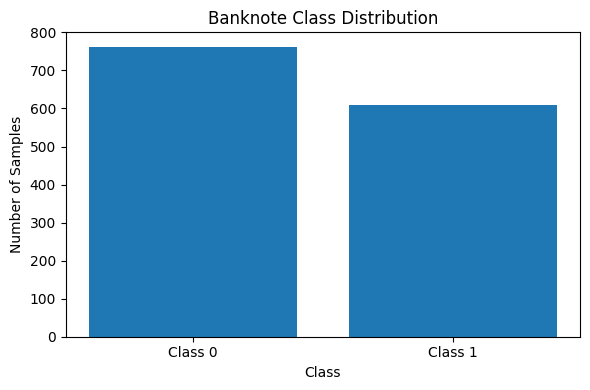

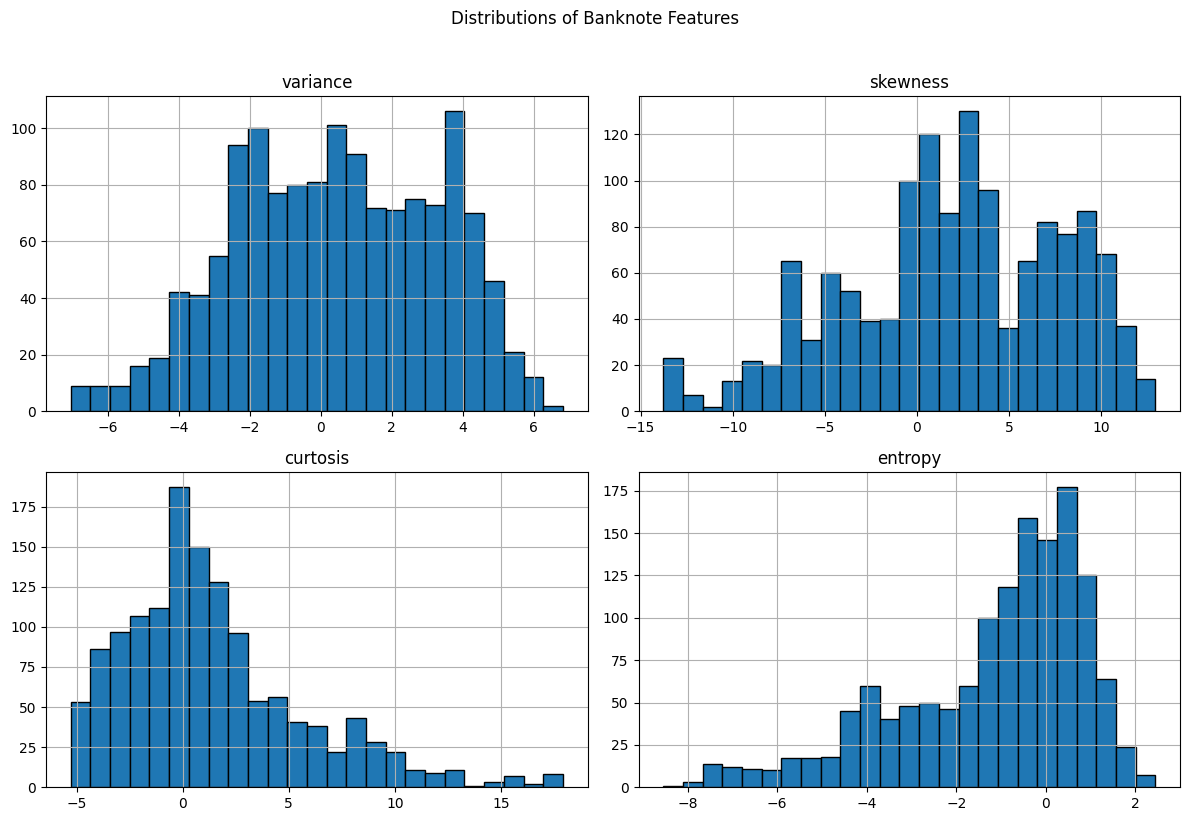

In [4]:
display(df.iloc[:, :4].describe().T)

class_counts = df["class"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(class_counts.index.astype(str), class_counts.values)
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.title("Banknote Class Distribution")
plt.xticks([0, 1], ["Class 0", "Class 1"])
plt.tight_layout()
plt.show()

df.iloc[:, :4].hist(
    figsize=(12, 8),
    bins=25,
    edgecolor="black"
)

plt.suptitle("Distributions of Banknote Features", y=1.02)
plt.tight_layout()
plt.show()

## 4. Train-Test Split and Feature Selection

In [5]:
X_all = df[["variance", "skewness", "curtosis", "entropy"]].to_numpy(dtype=float)
y = df["class"].to_numpy(dtype=int)

X_train_all, X_test_all, y_train, y_test = train_test_split(
    X_all,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

feature_names_2d = ["variance", "skewness"]
feature_indices_2d = [0, 1]

X_train_2d = X_train_all[:, feature_indices_2d]
X_test_2d = X_test_all[:, feature_indices_2d]

print("Full training set:", X_train_all.shape)
print("Full testing set:", X_test_all.shape)
print("2D training set:", X_train_2d.shape)
print("2D testing set:", X_test_2d.shape)

print("\nTraining class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTesting class distribution:")
print(pd.Series(y_test).value_counts().sort_index())

Full training set: (1097, 4)
Full testing set: (275, 4)
2D training set: (1097, 2)
2D testing set: (275, 2)

Training class distribution:
0    609
1    488
Name: count, dtype: int64

Testing class distribution:
0    153
1    122
Name: count, dtype: int64


## Part A: Decision Tree from Scratch

### 5. Implementing Gini Impurity and Entropy

In [6]:
def gini_impurity(y_node):
    """
    Calculate Gini impurity for a node.
    """
    if len(y_node) == 0:
        return 0.0

    _, counts = np.unique(y_node, return_counts=True)
    probabilities = counts / len(y_node)

    return 1.0 - np.sum(probabilities ** 2)

def entropy_impurity(y_node):
    """
    Calculate entropy for a node.
    """
    if len(y_node) == 0:
        return 0.0

    _, counts = np.unique(y_node, return_counts=True)
    probabilities = counts / len(y_node)

    return -np.sum(probabilities * np.log2(probabilities))

def weighted_child_impurity(y_left, y_right, criterion="gini"):
    """
    Calculate weighted impurity after a split.
    """
    total_samples = len(y_left) + len(y_right)

    if total_samples == 0:
        return 0.0

    impurity_function = (
        gini_impurity if criterion == "gini"
        else entropy_impurity
    )

    left_weight = len(y_left) / total_samples
    right_weight = len(y_right) / total_samples

    return (
        left_weight * impurity_function(y_left)
        + right_weight * impurity_function(y_right)
    )

test_labels = np.array([0, 0, 1, 1])

print("Gini impurity:", gini_impurity(test_labels))
print("Entropy:", entropy_impurity(test_labels))

pure_labels = np.array([1, 1, 1, 1])

print("\nGini impurity (pure node):", gini_impurity(pure_labels))
print("Entropy (pure node):", entropy_impurity(pure_labels))

Gini impurity: 0.5
Entropy: 1.0

Gini impurity (pure node): 0.0
Entropy (pure node): -0.0


### 6. Finding the Best Split

In [7]:
def find_best_split(X_node, y_node, criterion="gini"):
    """
    Find the feature and threshold with the lowest weighted
    child impurity.

    Returns:
        best_feature, best_threshold, best_impurity
    """
    n_samples, n_features = X_node.shape

    if n_samples < 2:
        return None, None, None

    impurity_function = (
        gini_impurity if criterion == "gini"
        else entropy_impurity
    )

    best_feature = None
    best_threshold = None
    best_impurity = float("inf")

    for feature_idx in range(n_features):
        values = np.unique(X_node[:, feature_idx])

        if len(values) < 2:
            continue

        thresholds = (values[:-1] + values[1:]) / 2.0

        for threshold in thresholds:
            left_mask = X_node[:, feature_idx] <= threshold
            right_mask = ~left_mask

            y_left = y_node[left_mask]
            y_right = y_node[right_mask]

            if len(y_left) == 0 or len(y_right) == 0:
                continue

            split_impurity = weighted_child_impurity(
                y_left, y_right, criterion
            )

            if split_impurity < best_impurity:
                best_impurity = split_impurity
                best_feature = feature_idx
                best_threshold = threshold

    return best_feature, best_threshold, best_impurity

X_example = np.array([
    [1.0],
    [2.0],
    [3.0],
    [4.0]
])

y_example = np.array([0, 0, 1, 1])

feature, threshold, impurity = find_best_split(
    X_example,
    y_example,
    criterion="gini"
)

print("Best feature index:", feature)
print("Best threshold:", threshold)
print("Weighted child impurity:", impurity)
print("Parent Gini impurity:", gini_impurity(y_example))
print("Information gain:",
      gini_impurity(y_example) - impurity)

Best feature index: 0
Best threshold: 2.5
Weighted child impurity: 0.0
Parent Gini impurity: 0.5
Information gain: 0.5


### 7. Recursive Decision Tree Construction

In [8]:
class ManualDecisionTree:
    def __init__(
        self,
        criterion="gini",
        max_depth=5,
        min_samples_split=2,
        min_samples_leaf=1
    ):
        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.root = None
        self.n_features_in_ = None

    def _majority_class(self, y_node):
        classes, counts = np.unique(y_node, return_counts=True)
        return classes[np.argmax(counts)]

    def _build_tree(self, X_node, y_node, depth):
        node = {
            "prediction": self._majority_class(y_node),
            "samples": len(y_node),
            "impurity": (
                gini_impurity(y_node)
                if self.criterion == "gini"
                else entropy_impurity(y_node)
            ),
            "feature": None,
            "threshold": None,
            "left": None,
            "right": None
        }

        if (
            node["impurity"] == 0
            or depth >= self.max_depth
            or len(y_node) < self.min_samples_split
        ):
            return node

        feature, threshold, child_impurity = find_best_split(
            X_node, y_node, self.criterion
        )

        if feature is None:
            return node

        left_mask = X_node[:, feature] <= threshold
        right_mask = ~left_mask

        if (
            np.sum(left_mask) < self.min_samples_leaf
            or np.sum(right_mask) < self.min_samples_leaf
        ):
            return node

        node["feature"] = feature
        node["threshold"] = threshold
        node["information_gain"] = node["impurity"] - child_impurity

        node["left"] = self._build_tree(
            X_node[left_mask], y_node[left_mask], depth + 1
        )
        node["right"] = self._build_tree(
            X_node[right_mask], y_node[right_mask], depth + 1
        )

        return node

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)

        self.n_features_in_ = X.shape[1]
        self.root = self._build_tree(X, y, depth=0)
        return self

    def _predict_one(self, x, node):
        # Leaf node
        if node["feature"] is None:
            return node["prediction"]

        if x[node["feature"]] <= node["threshold"]:
            return self._predict_one(x, node["left"])
        else:
            return self._predict_one(x, node["right"])

    def predict(self, X):
        X = np.asarray(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(1, -1)

        return np.array([
            self._predict_one(x, self.root) for x in X
        ])

    def print_tree(self, node=None, depth=0, feature_names=None):
        if node is None:
            node = self.root

        indent = "  " * depth

        if node["feature"] is None:
            print(
                f"{indent}Leaf: predict={node['prediction']}, "
                f"samples={node['samples']}"
            )
            return

        feature_name = (
            feature_names[node["feature"]]
            if feature_names is not None
            else f"X[{node['feature']}]"
        )

        print(
            f"{indent}if {feature_name} <= "
            f"{node['threshold']:.4f}: "
            f"(samples={node['samples']}, "
            f"gain={node.get('information_gain', 0):.4f})"
        )

        self.print_tree(node["left"], depth + 1, feature_names)

        print(f"{indent}else:")

        self.print_tree(node["right"], depth + 1, feature_names)

### 8. Training and Evaluating the Manual Decision Tree

In [9]:
manual_tree = ManualDecisionTree(
    criterion="gini",
    max_depth=5,
    min_samples_split=2,
    min_samples_leaf=1
)

tree_start = time.perf_counter()

manual_tree.fit(X_train_2d, y_train)

tree_train_time = time.perf_counter() - tree_start

predict_start = time.perf_counter()

y_pred_manual_tree = manual_tree.predict(X_test_2d)

tree_predict_time = time.perf_counter() - predict_start

print("Manual Decision Tree Results (2 features)")
print("-----------------------------------------")
print("Accuracy:",
      accuracy_score(y_test, y_pred_manual_tree))
print("Precision:",
      precision_score(y_test, y_pred_manual_tree, zero_division=0))
print("Recall:",
      recall_score(y_test, y_pred_manual_tree, zero_division=0))
print("F1-score:",
      f1_score(y_test, y_pred_manual_tree, zero_division=0))
print("Training time:", round(tree_train_time, 4), "seconds")
print("Prediction time:", round(tree_predict_time, 6), "seconds")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_manual_tree, zero_division=0))

print("\nLearned Tree Rules:")
manual_tree.print_tree(feature_names=feature_names_2d)

Manual Decision Tree Results (2 features)
-----------------------------------------
Accuracy: 0.9309090909090909
Precision: 0.8814814814814815
Recall: 0.9754098360655737
F1-score: 0.9260700389105059
Training time: 0.8339 seconds
Prediction time: 0.000979 seconds

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.90      0.94       153
           1       0.88      0.98      0.93       122

    accuracy                           0.93       275
   macro avg       0.93      0.94      0.93       275
weighted avg       0.94      0.93      0.93       275


Learned Tree Rules:
if variance <= 0.7651: (samples=1097, gain=0.2421)
  if skewness <= 5.1608: (samples=593, gain=0.1489)
    if variance <= 0.3202: (samples=464, gain=0.0287)
      if variance <= -0.4586: (samples=413, gain=0.0052)
        if skewness <= 0.0548: (samples=346, gain=0.0020)
          Leaf: predict=1, samples=208
        else:
          Leaf: predict=1, samples=138
 

### 9. Visualizing the Manually Learned Decision Tree

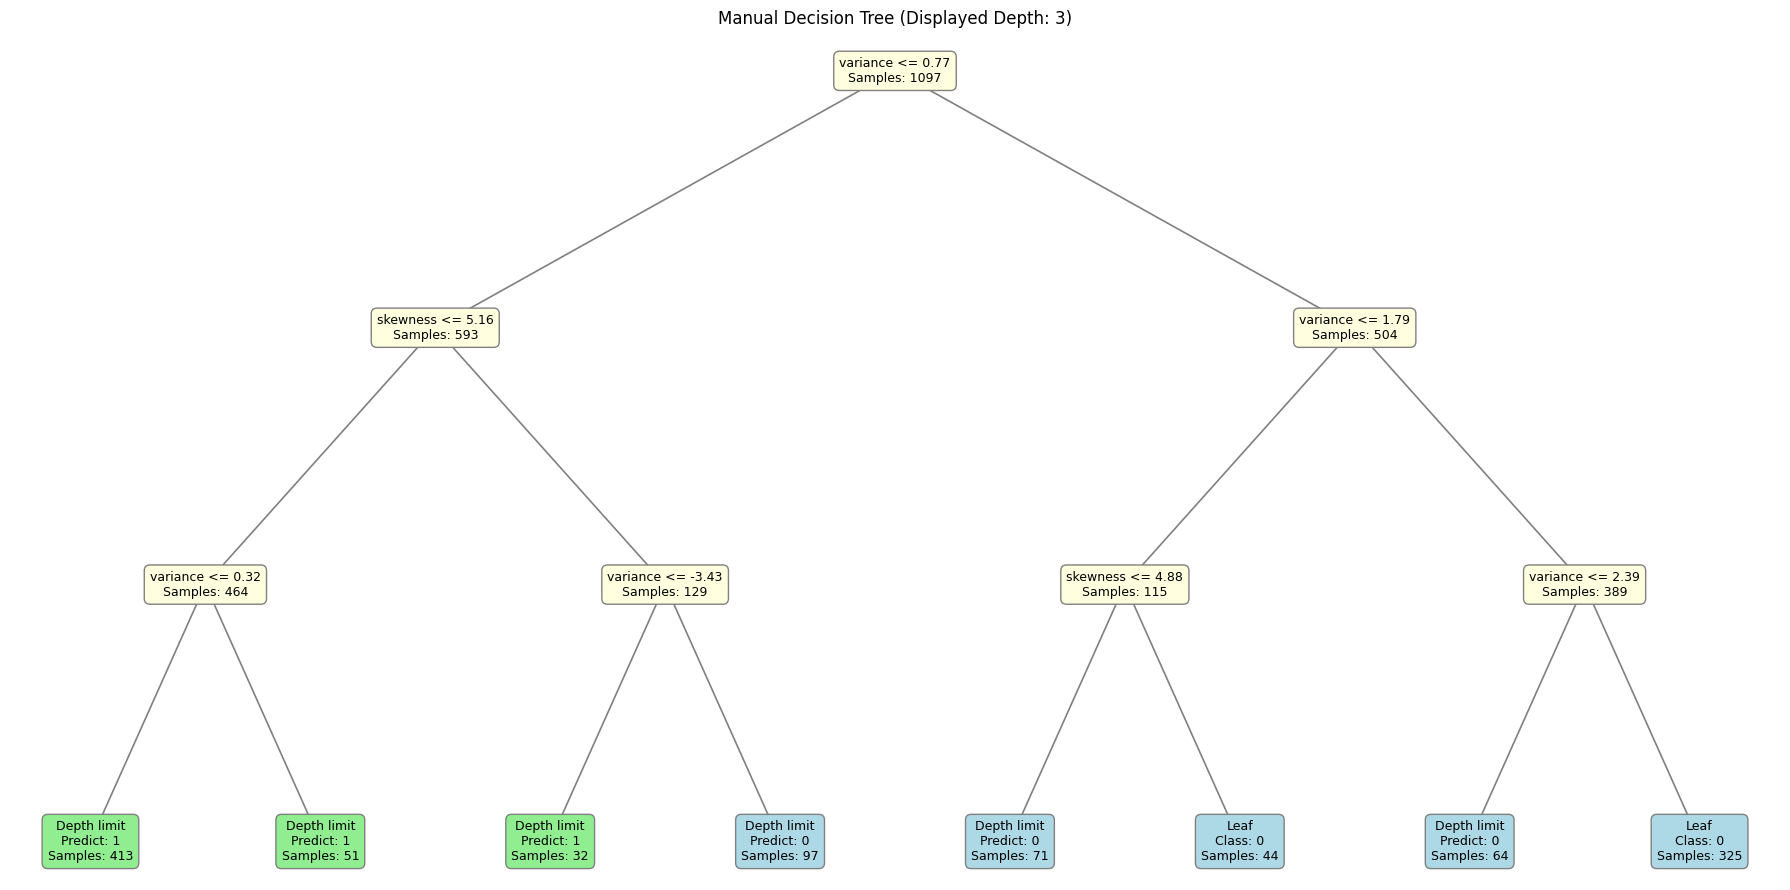

In [10]:
def plot_manual_tree(tree, feature_names, max_display_depth=3):
    fig, ax = plt.subplots(figsize=(18, 9))
    leaf_positions = [0]

    def count_leaves(node, depth):
        if node["feature"] is None or depth >= max_display_depth:
            return 1
        return (
            count_leaves(node["left"], depth + 1)
            + count_leaves(node["right"], depth + 1)
        )

    def draw_node(node, depth, x_left, x_right, parent_x=None, parent_y=None):
        x = (x_left + x_right) / 2
        y_pos = -depth

        if parent_x is not None:
            ax.plot([parent_x, x], [parent_y, y_pos],
                    color="gray", linewidth=1.2)

        if node["feature"] is None or depth >= max_display_depth:
            if node["feature"] is None:
                label = f"Leaf\nClass: {node['prediction']}\nSamples: {node['samples']}"
            else:
                label = (
                    f"Depth limit\nPredict: {node['prediction']}\n"
                    f"Samples: {node['samples']}"
                )
            color = "lightgreen" if node["prediction"] == 1 else "lightblue"
        else:
            label = (
                f"{feature_names[node['feature']]} <= "
                f"{node['threshold']:.2f}\n"
                f"Samples: {node['samples']}"
            )
            color = "lightyellow"

        ax.text(
            x, y_pos, label,
            ha="center", va="center", fontsize=9,
            bbox=dict(boxstyle="round,pad=0.45",
                      facecolor=color, edgecolor="gray")
        )

        if node["feature"] is not None and depth < max_display_depth:
            left_leaves = count_leaves(node["left"], depth + 1)
            right_leaves = count_leaves(node["right"], depth + 1)
            total = left_leaves + right_leaves
            split_x = x_left + (x_right - x_left) * left_leaves / total

            draw_node(
                node["left"], depth + 1,
                x_left, split_x, x, y_pos
            )
            draw_node(
                node["right"], depth + 1,
                split_x, x_right, x, y_pos
            )

    total_leaves = count_leaves(tree.root, 0)
    draw_node(tree.root, 0, 0, total_leaves)

    ax.set_title("Manual Decision Tree (Displayed Depth: 3)")
    ax.axis("off")
    plt.tight_layout()
    plt.show()


plot_manual_tree(manual_tree, feature_names_2d, max_display_depth=3)

### 10. Decision Boundary of the Manual Decision Tree

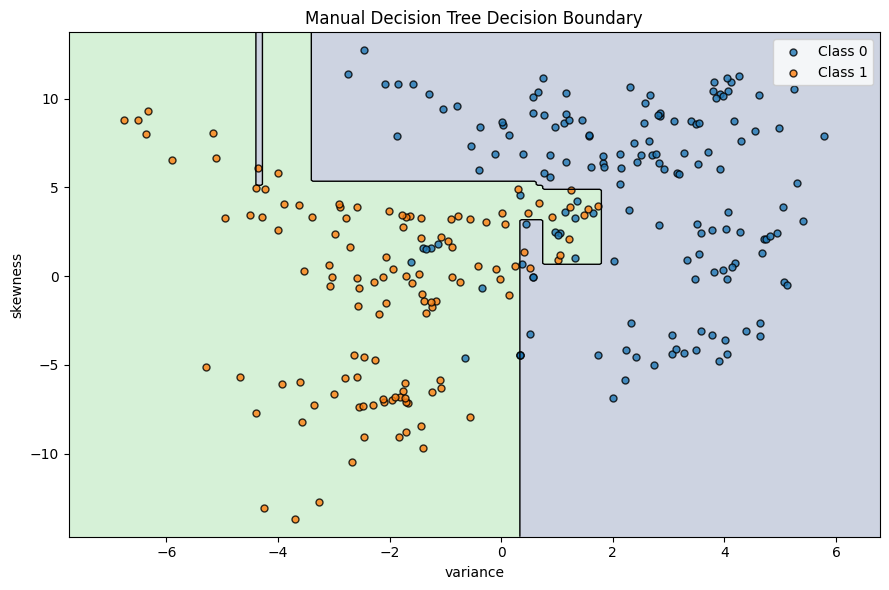

In [11]:
def plot_decision_boundary_2d(model, X, y, title, feature_names):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 250),
        np.linspace(y_min, y_max, 250)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid).reshape(xx.shape)

    plt.figure(figsize=(9, 6))
    plt.contourf(xx, yy, Z, alpha=0.25, levels=[-0.5, 0.5, 1.5])
    plt.contour(xx, yy, Z, levels=[0.5], colors="black", linewidths=1)

    for class_label in np.unique(y):
        mask = y == class_label
        plt.scatter(
            X[mask, 0], X[mask, 1],
            label=f"Class {class_label}",
            edgecolors="black", s=25, alpha=0.8
        )

    plt.xlabel(feature_names[0])
    plt.ylabel(feature_names[1])
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()


plot_decision_boundary_2d(
    manual_tree,
    X_test_2d,
    y_test,
    "Manual Decision Tree Decision Boundary",
    feature_names_2d
)

### 11. Scikit-learn Decision Tree Comparison

,Model,Accuracy,Precision,Recall,F1-score,Training Time (s),Prediction Time (s)
0,Manual Decision Tree,0.9309,0.8815,0.9754,0.9261,0.8339,0.0010
1,Scikit-learn Decision Tree,0.9309,0.8815,0.9754,0.9261,0.0166,0.0013


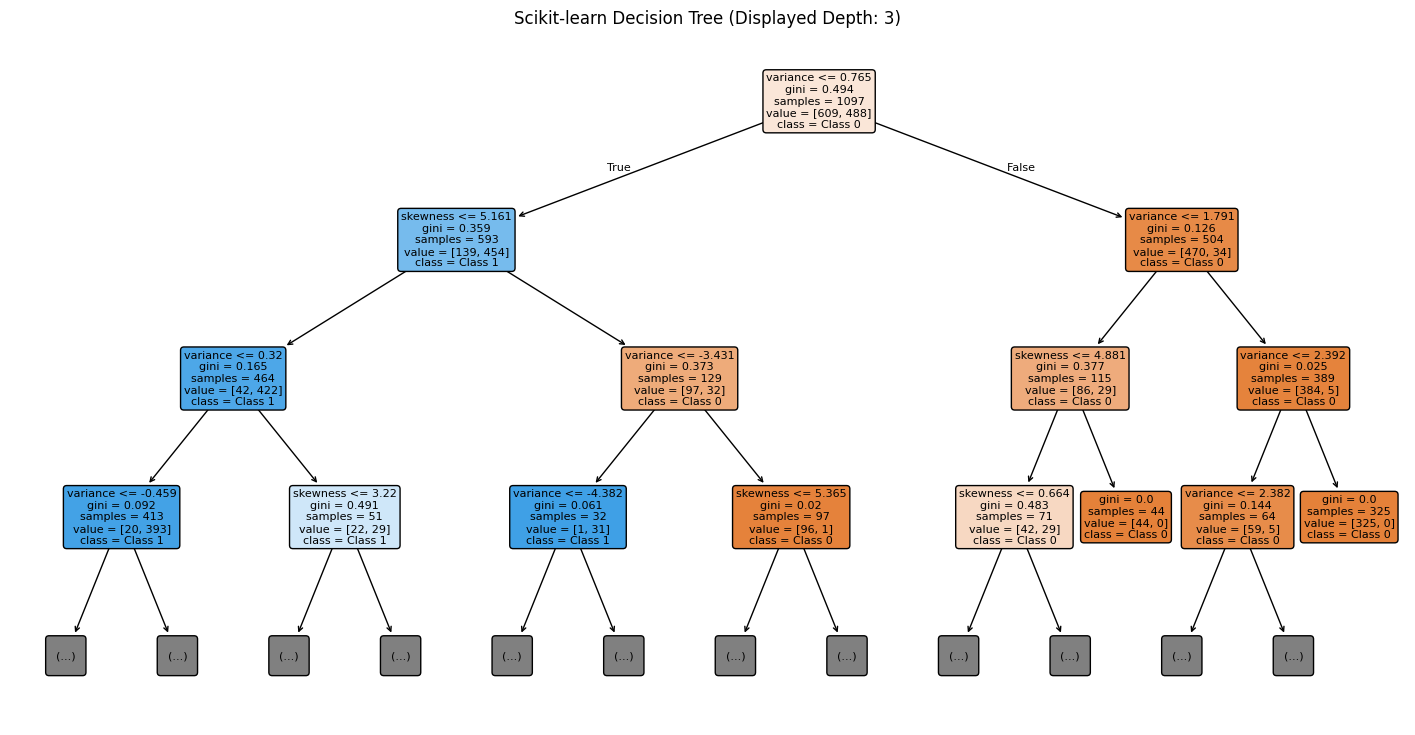

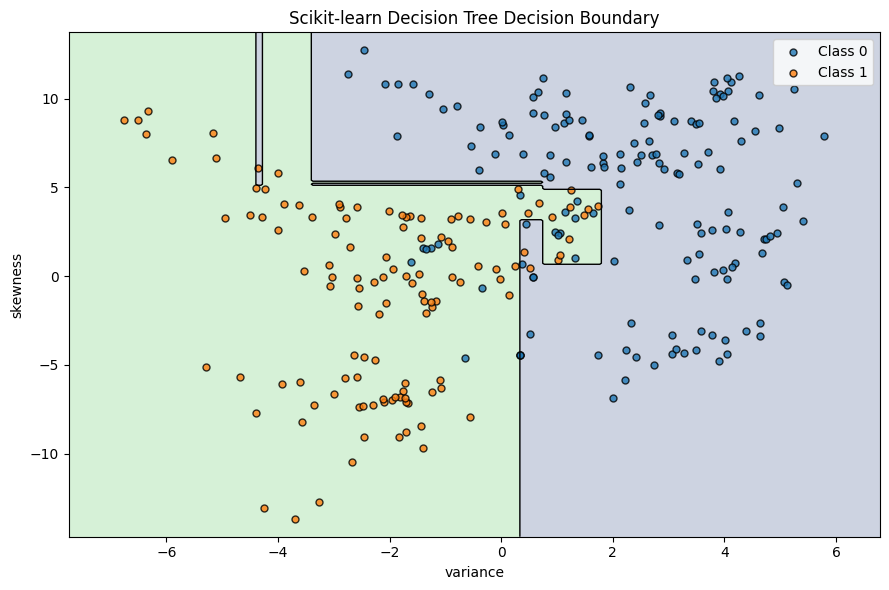

In [12]:
sklearn_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42
)

sk_tree_start = time.perf_counter()
sklearn_tree.fit(X_train_2d, y_train)
sk_tree_train_time = time.perf_counter() - sk_tree_start

sk_tree_predict_start = time.perf_counter()
y_pred_sklearn_tree = sklearn_tree.predict(X_test_2d)
sk_tree_predict_time = time.perf_counter() - sk_tree_predict_start

tree_comparison = pd.DataFrame({
    "Model": ["Manual Decision Tree", "Scikit-learn Decision Tree"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_manual_tree),
        accuracy_score(y_test, y_pred_sklearn_tree)
    ],
    "Precision": [
        precision_score(y_test, y_pred_manual_tree, zero_division=0),
        precision_score(y_test, y_pred_sklearn_tree, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred_manual_tree, zero_division=0),
        recall_score(y_test, y_pred_sklearn_tree, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, y_pred_manual_tree, zero_division=0),
        f1_score(y_test, y_pred_sklearn_tree, zero_division=0)
    ],
    "Training Time (s)": [tree_train_time, sk_tree_train_time],
    "Prediction Time (s)": [tree_predict_time, sk_tree_predict_time]
})

display(tree_comparison.round(4))

plt.figure(figsize=(18, 9))
plot_tree(
    sklearn_tree,
    feature_names=feature_names_2d,
    class_names=["Class 0", "Class 1"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)
plt.title("Scikit-learn Decision Tree (Displayed Depth: 3)")
plt.show()

plot_decision_boundary_2d(
    sklearn_tree,
    X_test_2d,
    y_test,
    "Scikit-learn Decision Tree Decision Boundary",
    feature_names_2d
)

### 12. Effect of Criterion and Maximum Depth

In [13]:
depth_values = [2, 3, 5]
criterion_values = ["gini", "entropy"]

depth_criterion_results = []

for criterion_name in criterion_values:
    for depth_value in depth_values:
        manual_model = ManualDecisionTree(
            criterion=criterion_name,
            max_depth=depth_value
        )

        start = time.perf_counter()
        manual_model.fit(X_train_2d, y_train)
        manual_fit_time = time.perf_counter() - start

        start = time.perf_counter()
        manual_predictions = manual_model.predict(X_test_2d)
        manual_pred_time = time.perf_counter() - start

        sklearn_model = DecisionTreeClassifier(
            criterion=criterion_name,
            max_depth=depth_value,
            random_state=42
        )

        start = time.perf_counter()
        sklearn_model.fit(X_train_2d, y_train)
        sklearn_fit_time = time.perf_counter() - start

        start = time.perf_counter()
        sklearn_predictions = sklearn_model.predict(X_test_2d)
        sklearn_pred_time = time.perf_counter() - start

        depth_criterion_results.append({
            "Criterion": criterion_name,
            "Max Depth": depth_value,
            "Manual Accuracy": accuracy_score(
                y_test, manual_predictions
            ),
            "Sklearn Accuracy": accuracy_score(
                y_test, sklearn_predictions
            ),
            "Manual F1": f1_score(
                y_test, manual_predictions, zero_division=0
            ),
            "Sklearn F1": f1_score(
                y_test, sklearn_predictions, zero_division=0
            ),
            "Prediction Agreement": np.mean(
                manual_predictions == sklearn_predictions
            ),
            "Manual Train (s)": manual_fit_time,
            "Sklearn Train (s)": sklearn_fit_time,
            "Manual Predict (s)": manual_pred_time,
            "Sklearn Predict (s)": sklearn_pred_time
        })

depth_criterion_df = pd.DataFrame(depth_criterion_results)

display(depth_criterion_df.round(4))

,Criterion,Max Depth,Manual Accuracy,Sklearn Accuracy,Manual F1,Sklearn F1,Prediction Agreement,Manual Train (s),Sklearn Train (s),Manual Predict (s),Sklearn Predict (s)
0,gini,2,0.8764,0.8764,0.8595,0.8595,1.0,0.3497,0.0031,0.0004,0.0003
1,gini,3,0.9091,0.9091,0.9004,0.9004,1.0,0.4635,0.0028,0.0005,0.0003
2,gini,5,0.9309,0.9309,0.9261,0.9261,1.0,0.5866,0.0031,0.0007,0.0003
3,entropy,2,0.8764,0.8764,0.8595,0.8595,1.0,0.2687,0.0020,0.0004,0.0002
4,entropy,3,0.9091,0.9091,0.9004,0.9004,1.0,0.3859,0.0023,0.0003,0.0002
5,entropy,5,0.9345,0.9345,0.9286,0.9286,1.0,0.6346,0.0026,0.0004,0.0002


### Observations

Compare how the criterion and maximum depth affect test accuracy and F1-score. Deeper trees can capture more complex decision boundaries but may overfit the training data. Gini and entropy may select different splits, although they can sometimes produce similar predictions.

## Part B: Linear SVM from Scratch

### 13. Feature Scaling and Label Encoding

In [14]:
svm_mean = X_train_2d.mean(axis=0)
svm_std = X_train_2d.std(axis=0)

svm_std[svm_std == 0] = 1.0

X_train_svm = (X_train_2d - svm_mean) / svm_std
X_test_svm = (X_test_2d - svm_mean) / svm_std

y_train_svm = np.where(y_train == 1, 1, -1)
y_test_svm = np.where(y_test == 1, 1, -1)

print("Training features shape:", X_train_svm.shape)
print("Testing features shape:", X_test_svm.shape)
print("Training labels:", np.unique(y_train_svm))
print("Testing labels:", np.unique(y_test_svm))
print("Training feature means:", X_train_svm.mean(axis=0).round(4))
print("Training feature standard deviations:",
      X_train_svm.std(axis=0).round(4))

Training features shape: (1097, 2)
Testing features shape: (275, 2)
Training labels: [-1  1]
Testing labels: [-1  1]
Training feature means: [-0.  0.]
Training feature standard deviations: [1. 1.]


### 14. Linear SVM Implementation Using NumPy

In [15]:
class ManualLinearSVM:
    def __init__(self, C=1.0, learning_rate=0.001, n_iterations=5000):
        self.C = C
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.weights = None
        self.bias = 0.0
        self.loss_history = []

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)

        n_samples, n_features = X.shape

        self.weights = np.zeros(n_features, dtype=float)
        self.bias = 0.0
        self.loss_history = []

        for iteration in range(self.n_iterations):
            margins = y * (X @ self.weights + self.bias)
            violating = margins < 1.0

            # Objective: 0.5 * ||w||^2 + C * mean(hinge loss)
            if np.any(violating):
                grad_w = (
                    self.weights
                    - self.C * np.mean(
                        (y[violating, None] * X[violating]),
                        axis=0
                    ) * (np.sum(violating) / n_samples)
                )

                grad_b = (
                    -self.C * np.sum(y[violating]) / n_samples
                )
            else:
                grad_w = self.weights.copy()
                grad_b = 0.0

            self.weights -= self.learning_rate * grad_w
            self.bias -= self.learning_rate * grad_b

            if iteration % 100 == 0 or iteration == self.n_iterations - 1:
                updated_margins = y * (
                    X @ self.weights + self.bias
                )
                hinge_loss = np.maximum(0, 1 - updated_margins).mean()
                objective = (
                    0.5 * np.dot(self.weights, self.weights)
                    + self.C * hinge_loss
                )
                self.loss_history.append(objective)

        return self

    def decision_function(self, X):
        X = np.asarray(X, dtype=float)
        return X @ self.weights + self.bias

    def predict(self, X):
        scores = self.decision_function(X)
        # Convert SVM labels back to dataset labels 0 and 1
        return np.where(scores >= 0, 1, 0)

### 15. Training and Evaluating the Manual Linear SVM

Manual Linear SVM Results (2 features)
--------------------------------------
Accuracy: 0.8654545454545455
Precision: 0.912621359223301
Recall: 0.7704918032786885
F1-score: 0.8355555555555556
Training time: 0.8241 seconds
Prediction time: 0.000171 seconds
Weights: [-0.502542   -0.25609766]
Bias: -0.26505742935276694


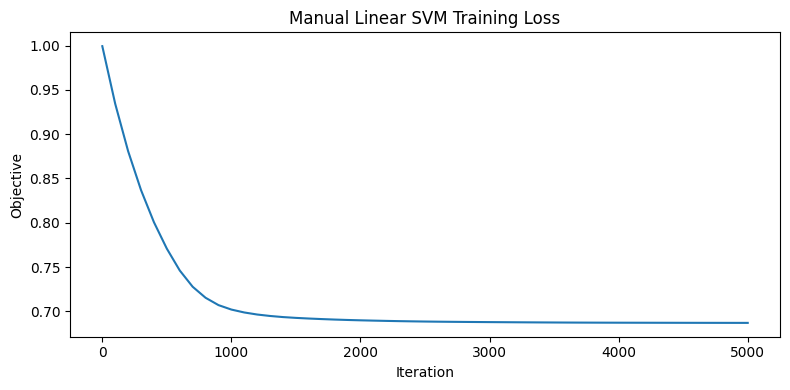

In [16]:

manual_svm = ManualLinearSVM(
    C=1.0,
    learning_rate=0.001,
    n_iterations=5000
)

svm_train_start = time.perf_counter()
manual_svm.fit(X_train_svm, y_train_svm)
svm_train_time = time.perf_counter() - svm_train_start

svm_predict_start = time.perf_counter()
y_pred_manual_svm = manual_svm.predict(X_test_svm)
svm_predict_time = time.perf_counter() - svm_predict_start

print("Manual Linear SVM Results (2 features)")
print("--------------------------------------")
print("Accuracy:",
      accuracy_score(y_test, y_pred_manual_svm))
print("Precision:",
      precision_score(y_test, y_pred_manual_svm, zero_division=0))
print("Recall:",
      recall_score(y_test, y_pred_manual_svm, zero_division=0))
print("F1-score:",
      f1_score(y_test, y_pred_manual_svm, zero_division=0))
print("Training time:", round(svm_train_time, 4), "seconds")
print("Prediction time:", round(svm_predict_time, 6), "seconds")
print("Weights:", manual_svm.weights)
print("Bias:", manual_svm.bias)

plt.figure(figsize=(8, 4))
plt.plot(
    np.arange(len(manual_svm.loss_history)) * 100,
    manual_svm.loss_history
)
plt.xlabel("Iteration")
plt.ylabel("Objective")
plt.title("Manual Linear SVM Training Loss")
plt.tight_layout()
plt.show()


### 16. Visualizing the SVM Decision Boundary and Margins

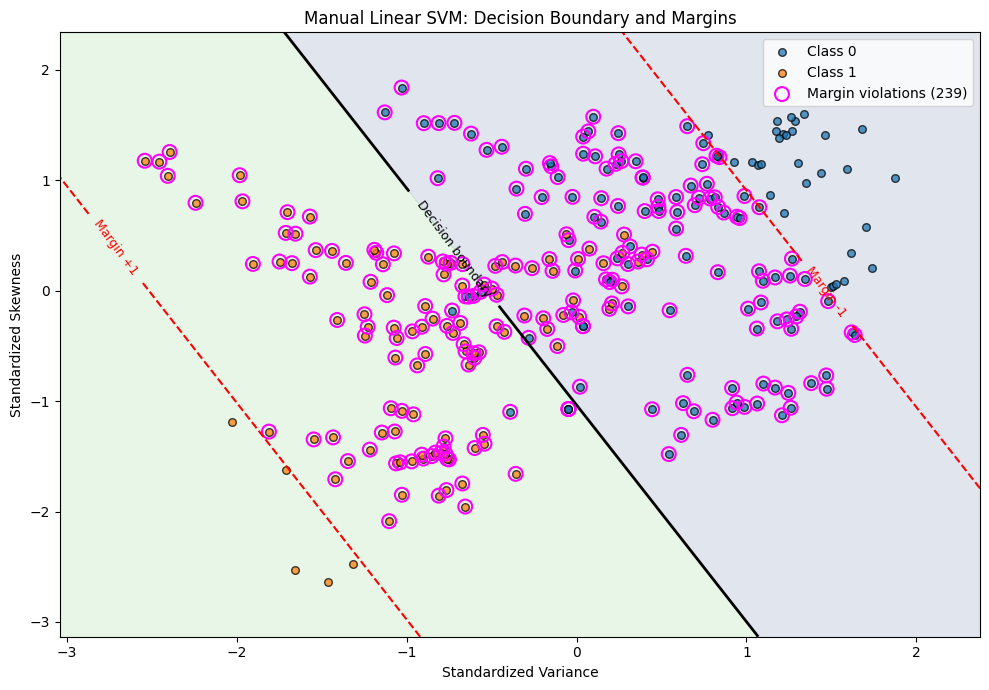

Number of margin-violating test samples: 239
Number of test samples: 275
Number of misclassified test samples: 37


In [17]:
# Generate a grid in the scaled feature space
svm_x_min = X_test_svm[:, 0].min() - 0.5
svm_x_max = X_test_svm[:, 0].max() + 0.5
svm_y_min = X_test_svm[:, 1].min() - 0.5
svm_y_max = X_test_svm[:, 1].max() + 0.5

svm_xx, svm_yy = np.meshgrid(
    np.linspace(svm_x_min, svm_x_max, 300),
    np.linspace(svm_y_min, svm_y_max, 300)
)

svm_grid = np.c_[svm_xx.ravel(), svm_yy.ravel()]
svm_scores_grid = manual_svm.decision_function(svm_grid).reshape(
    svm_xx.shape
)

# Decision scores for test samples
test_scores = manual_svm.decision_function(X_test_svm)

# Margin condition: y * f(x) >= 1
margin_values = y_test_svm * test_scores
margin_violations = margin_values < 1.0

plt.figure(figsize=(10, 7))

# Background classification regions
plt.contourf(
    svm_xx,
    svm_yy,
    svm_scores_grid,
    levels=[-100, 0, 100],
    alpha=0.15
)

# Margins: -1 and +1; decision boundary: 0
contours = plt.contour(
    svm_xx,
    svm_yy,
    svm_scores_grid,
    levels=[-1, 0, 1],
    colors=["red", "black", "red"],
    linestyles=["--", "-", "--"],
    linewidths=[1.5, 2.0, 1.5]
)

plt.clabel(
    contours,
    fmt={-1: "Margin -1", 0: "Decision boundary", 1: "Margin +1"},
    inline=True,
    fontsize=9
)

# Plot each true class
for class_label, svm_label in [(0, -1), (1, 1)]:
    class_mask = y_test_svm == svm_label
    plt.scatter(
        X_test_svm[class_mask, 0],
        X_test_svm[class_mask, 1],
        label=f"Class {class_label}",
        s=30,
        alpha=0.75,
        edgecolors="black"
    )

# Highlight margin-violating test samples
plt.scatter(
    X_test_svm[margin_violations, 0],
    X_test_svm[margin_violations, 1],
    s=100,
    facecolors="none",
    edgecolors="magenta",
    linewidths=1.5,
    label=f"Margin violations ({margin_violations.sum()})"
)

plt.xlabel("Standardized Variance")
plt.ylabel("Standardized Skewness")
plt.title("Manual Linear SVM: Decision Boundary and Margins")
plt.legend()
plt.tight_layout()
plt.show()

print("Number of margin-violating test samples:",
      int(margin_violations.sum()))
print("Number of test samples:", len(y_test))
print("Number of misclassified test samples:",
      int(np.sum(y_pred_manual_svm != y_test)))

### 17. Comparison with Scikit-learn Linear SVM

,Model,Accuracy,Precision,Recall,F1-score,Training Time (s),Prediction Time (s)
0,Manual Linear SVM,0.8655,0.9126,0.7705,0.8356,0.8241,0.0002
1,Scikit-learn Linear SVM,0.8764,0.8492,0.8770,0.8629,0.0254,0.0031


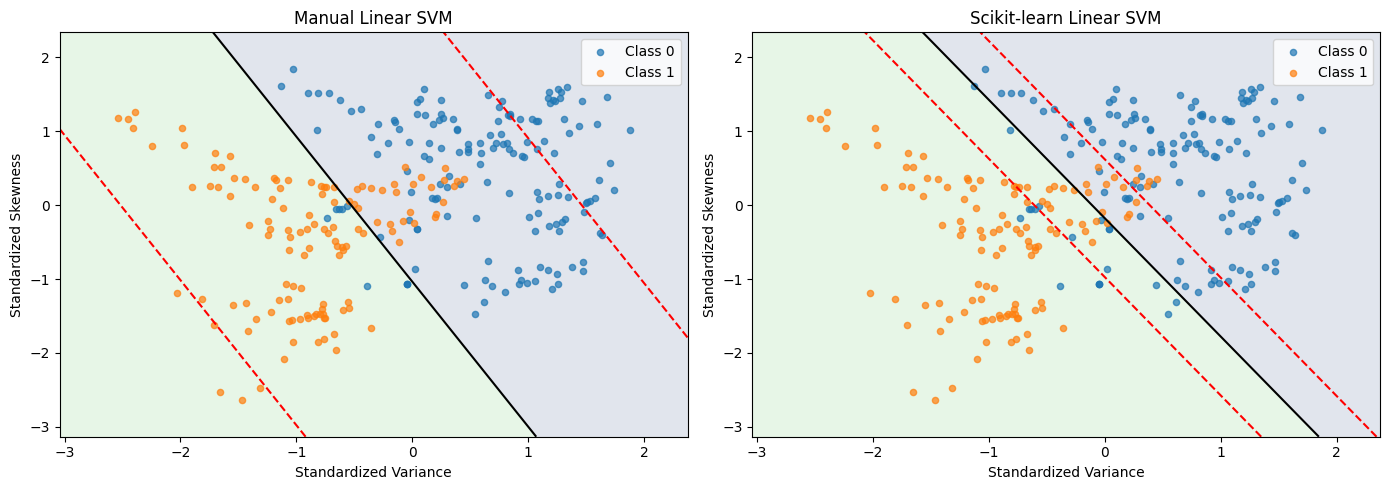

In [18]:
sklearn_svm = SVC(
    kernel="linear",
    C=1.0
)

sk_svm_train_start = time.perf_counter()
sklearn_svm.fit(X_train_svm, y_train_svm)
sk_svm_train_time = time.perf_counter() - sk_svm_train_start

sk_svm_predict_start = time.perf_counter()
y_pred_sklearn_svm = sklearn_svm.predict(X_test_svm)
sk_svm_predict_time = time.perf_counter() - sk_svm_predict_start

# Convert -1/+1 predictions back to 0/1
y_pred_sklearn_svm = np.where(y_pred_sklearn_svm == 1, 1, 0)

svm_comparison = pd.DataFrame({
    "Model": ["Manual Linear SVM", "Scikit-learn Linear SVM"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_manual_svm),
        accuracy_score(y_test, y_pred_sklearn_svm)
    ],
    "Precision": [
        precision_score(y_test, y_pred_manual_svm, zero_division=0),
        precision_score(y_test, y_pred_sklearn_svm, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred_manual_svm, zero_division=0),
        recall_score(y_test, y_pred_sklearn_svm, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, y_pred_manual_svm, zero_division=0),
        f1_score(y_test, y_pred_sklearn_svm, zero_division=0)
    ],
    "Training Time (s)": [
        svm_train_time, sk_svm_train_time
    ],
    "Prediction Time (s)": [
        svm_predict_time, sk_svm_predict_time
    ]
})

display(svm_comparison.round(4))

# Compare both models' decision boundaries
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, model, title in [
    (axes[0], manual_svm, "Manual Linear SVM"),
    (axes[1], sklearn_svm, "Scikit-learn Linear SVM")
]:
    scores = model.decision_function(svm_grid).reshape(svm_xx.shape)

    ax.contourf(
        svm_xx, svm_yy, scores,
        levels=[-100, 0, 100],
        alpha=0.15
    )

    ax.contour(
        svm_xx, svm_yy, scores,
        levels=[-1, 0, 1],
        colors=["red", "black", "red"],
        linestyles=["--", "-", "--"]
    )

    for class_label, svm_label in [(0, -1), (1, 1)]:
        mask = y_test_svm == svm_label
        ax.scatter(
            X_test_svm[mask, 0],
            X_test_svm[mask, 1],
            label=f"Class {class_label}",
            s=20,
            alpha=0.7
        )

    ax.set_xlabel("Standardized Variance")
    ax.set_ylabel("Standardized Skewness")
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.show()

### 18. Effect of Regularization Parameter C

In [19]:

C_values = [0.1, 1.0, 10.0]
C_results = []

for C_value in C_values:
    model = ManualLinearSVM(
        C=C_value,
        learning_rate=0.001,
        n_iterations=5000
    )

    start = time.perf_counter()
    model.fit(X_train_svm, y_train_svm)
    train_time = time.perf_counter() - start

    predictions = model.predict(X_test_svm)

    C_results.append({
        "C": C_value,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
        "Training Time (s)": train_time,
        "Weight Norm": np.linalg.norm(model.weights)
    })

C_results_df = pd.DataFrame(C_results)
display(C_results_df.round(4))


,C,Accuracy,Precision,Recall,F1-score,Training Time (s),Weight Norm
0,0.1,0.8582,0.9770,0.6967,0.8134,0.7417,0.0834
1,1.0,0.8655,0.9126,0.7705,0.8356,0.7267,0.5640
2,10.0,0.8873,0.8957,0.8443,0.8692,0.5096,1.2178


### 19. Effect of Learning Rate

In [20]:

learning_rates = [0.0005, 0.001, 0.005]
learning_rate_results = []

for lr in learning_rates:
    model = ManualLinearSVM(
        C=1.0,
        learning_rate=lr,
        n_iterations=5000
    )

    start = time.perf_counter()
    model.fit(X_train_svm, y_train_svm)
    train_time = time.perf_counter() - start

    predictions = model.predict(X_test_svm)

    learning_rate_results.append({
        "Learning Rate": lr,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
        "Training Time (s)": train_time,
        "Final Objective": model.loss_history[-1]
    })

learning_rate_results_df = pd.DataFrame(learning_rate_results)
display(learning_rate_results_df.round(4))


,Learning Rate,Accuracy,Precision,Recall,F1-score,Training Time (s),Final Objective
0,0.0005,0.8727,0.8991,0.8033,0.8485,0.6655,0.6884
1,0.0010,0.8655,0.9126,0.7705,0.8356,0.6292,0.6869
2,0.0050,0.8655,0.9208,0.7623,0.8341,0.6095,0.6868


### 20. Effect of Number of Iterations

In [21]:

iteration_values = [1000, 3000, 5000, 10000]
iteration_results = []

for n_iter in iteration_values:
    model = ManualLinearSVM(
        C=1.0,
        learning_rate=0.001,
        n_iterations=n_iter
    )

    start = time.perf_counter()
    model.fit(X_train_svm, y_train_svm)
    train_time = time.perf_counter() - start

    predictions = model.predict(X_test_svm)

    iteration_results.append({
        "Iterations": n_iter,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
        "Training Time (s)": train_time,
        "Final Objective": model.loss_history[-1]
    })

iteration_results_df = pd.DataFrame(iteration_results)
display(iteration_results_df.round(4))


,Iterations,Accuracy,Precision,Recall,F1-score,Training Time (s),Final Objective
0,1000,0.8873,0.8957,0.8443,0.8692,0.2017,0.7020
1,3000,0.8727,0.9065,0.7951,0.8472,0.4526,0.6878
2,5000,0.8655,0.9126,0.7705,0.8356,0.6820,0.6869
3,10000,0.8655,0.9208,0.7623,0.8341,1.3962,0.6868


## Part C: Kernel SVM and Nonlinear Decision Boundaries

### 21. Generating a Nonlinear Dataset

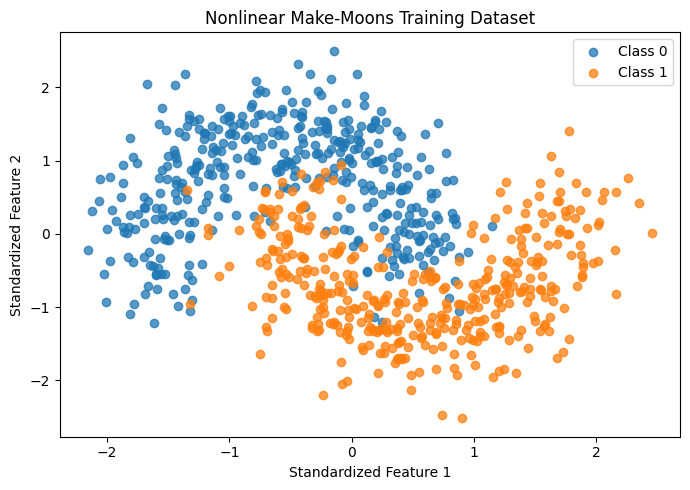

Training set: (800, 2)
Testing set: (200, 2)


In [22]:
# Generate a nonlinear two-class dataset
X_moons, y_moons = make_moons(
    n_samples=1000,
    noise=0.25,
    random_state=42
)

X_moons_train, X_moons_test, y_moons_train, y_moons_test = (
    train_test_split(
        X_moons,
        y_moons,
        test_size=0.20,
        random_state=42,
        stratify=y_moons
    )
)

# Standardize using training data only
moons_mean = X_moons_train.mean(axis=0)
moons_std = X_moons_train.std(axis=0)
moons_std[moons_std == 0] = 1.0

X_moons_train_scaled = (X_moons_train - moons_mean) / moons_std
X_moons_test_scaled = (X_moons_test - moons_mean) / moons_std

plt.figure(figsize=(7, 5))

for class_label in np.unique(y_moons_train):
    mask = y_moons_train == class_label
    plt.scatter(
        X_moons_train_scaled[mask, 0],
        X_moons_train_scaled[mask, 1],
        label=f"Class {class_label}",
        alpha=0.75
    )

plt.title("Nonlinear Make-Moons Training Dataset")
plt.xlabel("Standardized Feature 1")
plt.ylabel("Standardized Feature 2")
plt.legend()
plt.tight_layout()
plt.show()

print("Training set:", X_moons_train_scaled.shape)
print("Testing set:", X_moons_test_scaled.shape)

### 22. Comparing Linear, Polynomial and RBF Kernels

In [23]:

kernel_models = {
    "Linear": SVC(kernel="linear", C=1.0),
    "Polynomial (degree 3)": SVC(
        kernel="poly", degree=3, C=1.0, gamma="scale"
    ),
    "RBF": SVC(kernel="rbf", C=1.0, gamma="scale")
}

kernel_results = []
kernel_predictions = {}

for kernel_name, model in kernel_models.items():
    start = time.perf_counter()
    model.fit(X_moons_train_scaled, y_moons_train)
    train_time = time.perf_counter() - start

    start = time.perf_counter()
    predictions = model.predict(X_moons_test_scaled)
    predict_time = time.perf_counter() - start

    kernel_predictions[kernel_name] = predictions

    kernel_results.append({
        "Kernel": kernel_name,
        "Accuracy": accuracy_score(y_moons_test, predictions),
        "Precision": precision_score(
            y_moons_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_moons_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_moons_test, predictions, zero_division=0
        ),
        "Training Time (s)": train_time,
        "Prediction Time (s)": predict_time
    })

kernel_results_df = pd.DataFrame(kernel_results)
display(kernel_results_df.round(4))


,Kernel,Accuracy,Precision,Recall,F1-score,Training Time (s),Prediction Time (s)
0,Linear,0.915,0.9368,0.89,0.9128,0.0192,0.0019
1,Polynomial (degree 3),0.905,0.9010,0.91,0.9055,0.0117,0.0035
2,RBF,0.965,0.9604,0.97,0.9652,0.0126,0.0082


### 23. Visualizing Kernel Decision Boundaries

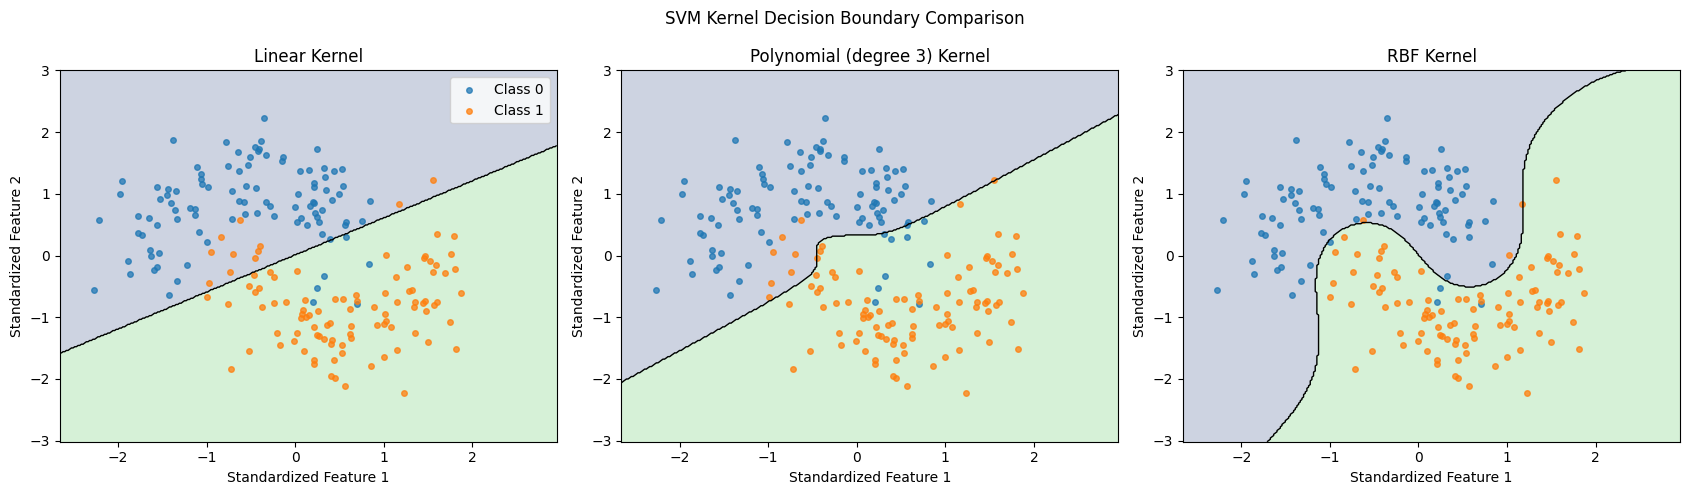

In [24]:

moon_x_min = X_moons_train_scaled[:, 0].min() - 0.5
moon_x_max = X_moons_train_scaled[:, 0].max() + 0.5
moon_y_min = X_moons_train_scaled[:, 1].min() - 0.5
moon_y_max = X_moons_train_scaled[:, 1].max() + 0.5

moon_xx, moon_yy = np.meshgrid(
    np.linspace(moon_x_min, moon_x_max, 300),
    np.linspace(moon_y_min, moon_y_max, 300)
)

moon_grid = np.c_[moon_xx.ravel(), moon_yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (kernel_name, model) in zip(
    axes, kernel_models.items()
):
    grid_predictions = model.predict(moon_grid).reshape(
        moon_xx.shape
    )

    ax.contourf(
        moon_xx,
        moon_yy,
        grid_predictions,
        levels=[-0.5, 0.5, 1.5],
        alpha=0.25
    )

    ax.contour(
        moon_xx,
        moon_yy,
        grid_predictions,
        levels=[0.5],
        colors="black",
        linewidths=1
    )

    for class_label in np.unique(y_moons_test):
        mask = y_moons_test == class_label
        ax.scatter(
            X_moons_test_scaled[mask, 0],
            X_moons_test_scaled[mask, 1],
            label=f"Class {class_label}",
            s=16,
            alpha=0.75
        )

    ax.set_title(f"{kernel_name} Kernel")
    ax.set_xlabel("Standardized Feature 1")
    ax.set_ylabel("Standardized Feature 2")

axes[0].legend()
plt.suptitle("SVM Kernel Decision Boundary Comparison")
plt.tight_layout()
plt.show()


### 24. Effect of Regularization on the RBF Kernel

In [25]:

rbf_C_results = []

for C_value in [0.1, 1.0, 10.0, 100.0]:
    model = SVC(
        kernel="rbf",
        C=C_value,
        gamma="scale"
    )

    start = time.perf_counter()
    model.fit(X_moons_train_scaled, y_moons_train)
    train_time = time.perf_counter() - start

    predictions = model.predict(X_moons_test_scaled)

    rbf_C_results.append({
        "C": C_value,
        "Accuracy": accuracy_score(y_moons_test, predictions),
        "Precision": precision_score(
            y_moons_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_moons_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_moons_test, predictions, zero_division=0
        ),
        "Training Time (s)": train_time
    })

rbf_C_results_df = pd.DataFrame(rbf_C_results)
display(rbf_C_results_df.round(4))


,C,Accuracy,Precision,Recall,F1-score,Training Time (s)
0,0.1,0.950,0.9500,0.95,0.9500,0.0127
1,1.0,0.965,0.9604,0.97,0.9652,0.0083
2,10.0,0.975,0.9612,0.99,0.9754,0.0162
3,100.0,0.975,0.9612,0.99,0.9754,0.0422


## Part D: Final Model Comparison Using All Four Features

### 25. Training Decision Tree Models

In [26]:

# Manual Decision Tree using all four features
final_manual_tree = ManualDecisionTree(
    criterion="gini",
    max_depth=5,
    min_samples_split=2,
    min_samples_leaf=1
)

start = time.perf_counter()
final_manual_tree.fit(X_train_all, y_train)
final_manual_tree_train_time = time.perf_counter() - start

start = time.perf_counter()
final_manual_tree_pred = final_manual_tree.predict(X_test_all)
final_manual_tree_predict_time = time.perf_counter() - start


# Scikit-learn Decision Tree using all four features
final_sklearn_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42
)

start = time.perf_counter()
final_sklearn_tree.fit(X_train_all, y_train)
final_sklearn_tree_train_time = time.perf_counter() - start

start = time.perf_counter()
final_sklearn_tree_pred = final_sklearn_tree.predict(X_test_all)
final_sklearn_tree_predict_time = time.perf_counter() - start


print("Manual Decision Tree accuracy:",
      round(accuracy_score(y_test, final_manual_tree_pred), 4))

print("Scikit-learn Decision Tree accuracy:",
      round(accuracy_score(y_test, final_sklearn_tree_pred), 4))

print("Prediction agreement:",
      round(np.mean(final_manual_tree_pred == final_sklearn_tree_pred), 4))


Manual Decision Tree accuracy: 0.9927
Scikit-learn Decision Tree accuracy: 0.9927
Prediction agreement: 1.0


### 26. Training Linear and Kernel SVM Models

In [27]:
# Standardize all four features using training statistics only
final_svm_mean = X_train_all.mean(axis=0)
final_svm_std = X_train_all.std(axis=0)
final_svm_std[final_svm_std == 0] = 1.0

X_train_all_svm = (X_train_all - final_svm_mean) / final_svm_std
X_test_all_svm = (X_test_all - final_svm_mean) / final_svm_std

# Encode labels as -1 and +1 for the manual SVM
y_train_all_svm = np.where(y_train == 1, 1, -1)

# Manual Linear SVM
final_manual_svm = ManualLinearSVM(
    C=1.0,
    learning_rate=0.001,
    n_iterations=5000
)

start = time.perf_counter()
final_manual_svm.fit(X_train_all_svm, y_train_all_svm)
final_manual_svm_train_time = time.perf_counter() - start

start = time.perf_counter()
final_manual_svm_pred = final_manual_svm.predict(X_test_all_svm)
final_manual_svm_predict_time = time.perf_counter() - start


# Scikit-learn SVM models
final_sklearn_svms = {
    "Scikit-learn Linear SVM": SVC(kernel="linear", C=1.0),
    "Polynomial SVM (degree 3)": SVC(
        kernel="poly", degree=3, C=1.0, gamma="scale"
    ),
    "RBF SVM": SVC(kernel="rbf", C=1.0, gamma="scale")
}

final_svm_predictions = {}
final_svm_times = {}

for model_name, model in final_sklearn_svms.items():
    start = time.perf_counter()
    model.fit(X_train_all_svm, y_train)
    fit_time = time.perf_counter() - start

    start = time.perf_counter()
    predictions = model.predict(X_test_all_svm)
    predict_time = time.perf_counter() - start

    final_svm_predictions[model_name] = predictions
    final_svm_times[model_name] = {
        "train": fit_time,
        "predict": predict_time
    }

print("All four-feature SVM models trained successfully.")
print("Training shape:", X_train_all_svm.shape)
print("Testing shape:", X_test_all_svm.shape)

All four-feature SVM models trained successfully.
Training shape: (1097, 4)
Testing shape: (275, 4)


### 27. Final Performance Comparison

In [28]:

final_model_results = []

def add_final_result(
    model_name, y_true, y_pred, train_time, predict_time
):
    final_model_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "Training Time (s)": train_time,
        "Prediction Time (s)": predict_time
    })


# Decision Tree results
add_final_result(
    "Manual Decision Tree",
    y_test,
    final_manual_tree_pred,
    final_manual_tree_train_time,
    final_manual_tree_predict_time
)

add_final_result(
    "Scikit-learn Decision Tree",
    y_test,
    final_sklearn_tree_pred,
    final_sklearn_tree_train_time,
    final_sklearn_tree_predict_time
)

# Manual SVM result
add_final_result(
    "Manual Linear SVM",
    y_test,
    final_manual_svm_pred,
    final_manual_svm_train_time,
    final_manual_svm_predict_time
)

# Scikit-learn SVM results
for model_name, predictions in final_svm_predictions.items():
    add_final_result(
        model_name,
        y_test,
        predictions,
        final_svm_times[model_name]["train"],
        final_svm_times[model_name]["predict"]
    )

final_comparison_df = pd.DataFrame(final_model_results)

display(
    final_comparison_df
    .sort_values("F1-score", ascending=False)
    .reset_index(drop=True)
    .round(4)
)

best_model_row = final_comparison_df.loc[
    final_comparison_df["F1-score"].idxmax()
]

print("\nBest model by F1-score:", best_model_row["Model"])
print("Best F1-score:", round(best_model_row["F1-score"], 4))


,Model,Accuracy,Precision,Recall,F1-score,Training Time (s),Prediction Time (s)
0,RBF SVM,1.0000,1.0000,1.0000,1.0000,0.0074,0.0032
1,Manual Decision Tree,0.9927,0.9839,1.0000,0.9919,1.2476,0.0005
2,Scikit-learn Decision Tree,0.9927,0.9839,1.0000,0.9919,0.0037,0.0003
3,Polynomial SVM (degree 3),0.9818,0.9606,1.0000,0.9799,0.0127,0.0024
4,Scikit-learn Linear SVM,0.9745,0.9457,1.0000,0.9721,0.0123,0.0021
5,Manual Linear SVM,0.8800,0.9238,0.7951,0.8546,0.7541,0.0002



Best model by F1-score: RBF SVM
Best F1-score: 1.0


### 28. Visual Comparison of Model Performance

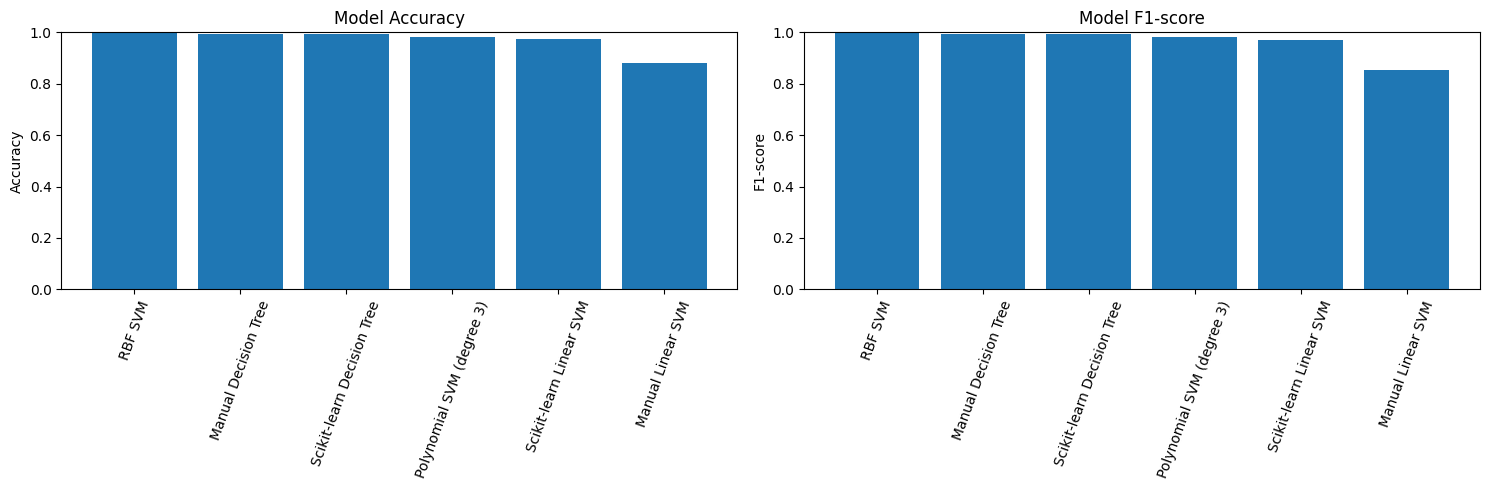

In [29]:

plot_df = final_comparison_df.sort_values(
    "F1-score", ascending=False
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].bar(plot_df["Model"], plot_df["Accuracy"])
axes[0].set_title("Model Accuracy")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=70)

axes[1].bar(plot_df["Model"], plot_df["F1-score"])
axes[1].set_title("Model F1-score")
axes[1].set_ylabel("F1-score")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=70)

plt.tight_layout()
plt.show()


### 30. Confusion Matrix for the Best Model

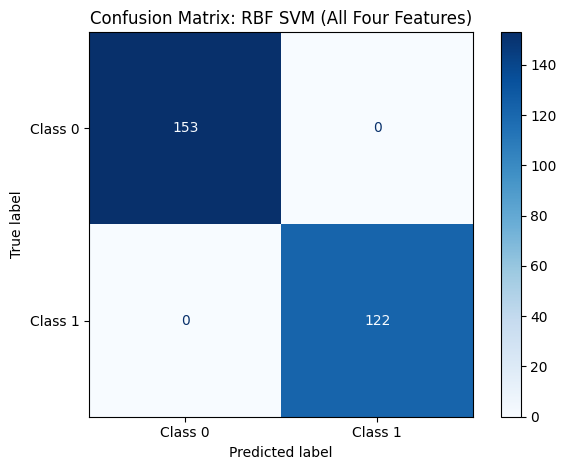

Correct predictions: 275
Total test samples: 275
Misclassified samples: 0


In [30]:

from sklearn.metrics import ConfusionMatrixDisplay

best_final_svm = final_sklearn_svms["RBF SVM"]

ConfusionMatrixDisplay.from_estimator(
    best_final_svm,
    X_test_all_svm,
    y_test,
    display_labels=["Class 0", "Class 1"],
    cmap="Blues"
)

plt.title("Confusion Matrix: RBF SVM (All Four Features)")
plt.tight_layout()
plt.show()

print("Correct predictions:",
      int(np.sum(final_svm_predictions["RBF SVM"] == y_test)))

print("Total test samples:", len(y_test))
print("Misclassified samples:",
      int(np.sum(final_svm_predictions["RBF SVM"] != y_test)))
